# Group 24: Predicting Rainfall in Abuja
## Week 1 – Data acquisition and first-look inspection

**Study period:** 2001-01-01 to 2025-12-31 (25 years)  
**Location:** Abuja, Nigeria (approximately 9.0765° N, 7.3986° E)  
**Source:** NASA POWER Daily Point API

Run the cells from top to bottom. The download cell retrieves the real data from NASA; it does not use simulated or made-up observations.

In [2]:
!pip install pandas requests matplotlib


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\PC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable

   ---------------------------------------- 0/4 [urllib3]
   ---------------------------------------- 0/4 [urllib3]
   ---------------------------------------- 0/4 [urllib3]
   ---------- ----------------------------- 1/4 [charset_normalizer]
   -------------------- ------------------- 2/4 [certifi]
   ------------------------------ --------- 3/4 [requests]
   ------------------------------ --------- 3/4 [requests]
   ---------------------------------------- 4/4 [requests]



In [3]:
import requests
import pandas as pd
from pathlib import Path
from datetime import date
import matplotlib.pyplot as plt

## 1. Download daily weather data from NASA POWER

In [5]:
import requests
import pandas as pd
from pathlib import Path
from datetime import date

BASE_URL = 'https://power.larc.nasa.gov/api/temporal/daily/point'
PARAMETERS = 'PRECTOTCORR,T2M,RH2M,WS10M,PS'   # PRECTOT -> PRECTOTCORR
REQUEST_PARAMS = {
    'parameters': PARAMETERS,
    'community': 'AG',                          # HY -> AG
    'longitude': 7.3986,
    'latitude': 9.0765,
    'start': '20010101',
    'end': '20251231',
    'format': 'JSON',
    'time-standard': 'UTC'
}

response = requests.get(BASE_URL, params=REQUEST_PARAMS, timeout=120)
if not response.ok:
    print(response.status_code, response.text)  # shows the API's actual complaint
response.raise_for_status()

power_data = response.json()
parameter_data = power_data['properties']['parameter']
units = {name: details.get('units') for name, details in power_data.get('parameters', {}).items()}

df = pd.DataFrame(parameter_data).rename_axis('DATE').reset_index()
df['DATE'] = pd.to_datetime(df['DATE'], format='%Y%m%d', errors='coerce')
df = df.replace(-999, pd.NA)   # NASA POWER uses -999 for missing values

csv_path = Path('abuja_nasa_power_daily_2001_2025.csv')
df.to_csv(csv_path, index=False)

print('Downloaded and saved:', csv_path.resolve())
print('Download date:', date.today())
print('Request URL:', response.url)
print('NASA parameter units:', units)

Downloaded and saved: C:\Users\PC\Downloads\abuja_nasa_power_daily_2001_2025.csv
Download date: 2026-11-09
Request URL: https://power.larc.nasa.gov/api/temporal/daily/point?parameters=PRECTOTCORR%2CT2M%2CRH2M%2CWS10M%2CPS&community=AG&longitude=7.3986&latitude=9.0765&start=20010101&end=20251231&format=JSON&time-standard=UTC
NASA parameter units: {'PRECTOTCORR': 'mm/day', 'T2M': 'C', 'RH2M': '%', 'WS10M': 'm/s', 'PS': 'kPa'}


## 2. Preview the downloaded dataset

In [6]:
display(df.head())

,DATE,PRECTOTCORR,T2M,RH2M,WS10M,PS
0,2001-01-01,0.0,21.03,55.60,2.46,96.57
1,2001-01-02,0.0,20.79,50.55,3.13,96.54
2,2001-01-03,0.0,20.37,49.07,2.83,96.63
3,2001-01-04,0.0,20.23,47.67,3.31,96.58
4,2001-01-05,0.0,19.53,54.13,3.32,96.60


## 3. First five rows and dataset shape

In [7]:
display(df.head())
print('Dataset shape (rows, columns):', df.shape)

,DATE,PRECTOTCORR,T2M,RH2M,WS10M,PS
0,2001-01-01,0.0,21.03,55.60,2.46,96.57
1,2001-01-02,0.0,20.79,50.55,3.13,96.54
2,2001-01-03,0.0,20.37,49.07,2.83,96.63
3,2001-01-04,0.0,20.23,47.67,3.31,96.58
4,2001-01-05,0.0,19.53,54.13,3.32,96.60


Dataset shape (rows, columns): (9131, 6)


## 4. First five rows and dataset shape

In [8]:
display(df.head())
print('Dataset shape (rows, columns):', df.shape)

,DATE,PRECTOTCORR,T2M,RH2M,WS10M,PS
0,2001-01-01,0.0,21.03,55.60,2.46,96.57
1,2001-01-02,0.0,20.79,50.55,3.13,96.54
2,2001-01-03,0.0,20.37,49.07,2.83,96.63
3,2001-01-04,0.0,20.23,47.67,3.31,96.58
4,2001-01-05,0.0,19.53,54.13,3.32,96.60


Dataset shape (rows, columns): (9131, 6)


## 5. Data types and general information

In [9]:
print(df.dtypes)
df.info()

DATE           datetime64[us]
PRECTOTCORR           float64
T2M                   float64
RH2M                  float64
WS10M                 float64
PS                    float64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 9131 entries, 0 to 9130
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   DATE         9131 non-null   datetime64[us]
 1   PRECTOTCORR  9131 non-null   float64       
 2   T2M          9131 non-null   float64       
 3   RH2M         9131 non-null   float64       
 4   WS10M        9131 non-null   float64       
 5   PS           9131 non-null   float64       
dtypes: datetime64[us](1), float64(5)
memory usage: 428.1 KB


## 6. Missing values

In [10]:
print('Missing values per column:')
print(df.isna().sum())
print('\nTotal missing values:', int(df.isna().sum().sum()))

Missing values per column:
DATE           0
PRECTOTCORR    0
T2M            0
RH2M           0
WS10M          0
PS             0
dtype: int64

Total missing values: 0


## 7. Replace NASA POWER fill values and check duplicates

In [11]:
numeric_cols = df.select_dtypes(include='number').columns
df[numeric_cols] = df[numeric_cols].replace(-999, pd.NA)
print('Missing values after replacing -999 fill values:')
print(df.isna().sum())
print('Duplicate rows:', df.duplicated().sum())

Missing values after replacing -999 fill values:
DATE           0
PRECTOTCORR    0
T2M            0
RH2M           0
WS10M          0
PS             0
dtype: int64
Duplicate rows: 0


## 8. Summary statistics

In [12]:
display(df.describe(include='all'))

,DATE,PRECTOTCORR,T2M,RH2M,WS10M,PS
count,9131,9131.000000,9131.000000,9131.000000,9131.000000,9131.000000
mean,2013-07-02 00:00:00,3.281360,25.696727,68.554381,2.363335,96.477157
min,2001-01-01 00:00:00,0.000000,19.530000,13.220000,0.580000,95.880000
25%,2007-04-02 12:00:00,0.000000,24.270000,53.675000,1.820000,96.370000
50%,2013-07-02 00:00:00,0.870000,25.350000,76.250000,2.280000,96.490000
75%,2019-10-01 12:00:00,4.240000,26.875000,85.500000,2.820000,96.590000
max,2025-12-31 00:00:00,130.170000,33.040000,95.370000,6.920000,96.950000
std,NaN,6.003966,2.047152,20.236646,0.746034,0.161049


## 9. Rainfall overview

count    9131.000000
mean        3.281360
std         6.003966
min         0.000000
25%         0.000000
50%         0.870000
75%         4.240000
max       130.170000
Name: PRECTOTCORR, dtype: float64


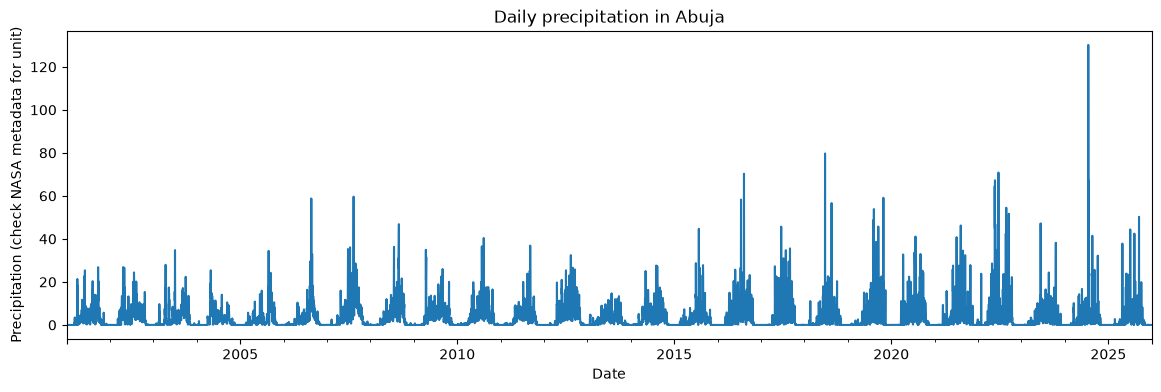

In [14]:
rain_col = 'PRECTOTCORR'
if rain_col in df.columns:
    print(df[rain_col].describe())
    df.set_index('DATE')[rain_col].plot(figsize=(14, 4), title='Daily precipitation in Abuja')
    plt.ylabel('Precipitation (check NASA metadata for unit)')
    plt.xlabel('Date')
    plt.show()
else:
    print('PRECTOT column not found. Check the returned column names and update rain_col.')

## 10. Save a cleaned working copy

This saves a copy after converting the date and replacing NASA's -999 fill values. Review column names and units before modelling.

In [15]:
clean_path = Path('abuja_weather_cleaned_firstlook.csv')
df.to_csv(clean_path, index=False)
print('Saved:', clean_path.resolve())

Saved: C:\Users\PC\Downloads\abuja_weather_cleaned_firstlook.csv


## Data dictionary

| Variable | Meaning | Unit |
|---|---|---|
| DATE | Daily observation date | YYYY-MM-DD |
| PRECTOT | Daily precipitation | mm/day (verify response metadata) |
| T2M | Mean air temperature at 2 metres | °C |
| RH2M | Mean relative humidity at 2 metres | % |
| WS10M | Mean wind speed at 10 metres | m/s |
| PS | Surface atmospheric pressure | kPa |

NASA POWER daily data are gridded/reanalysis-based estimates. The coordinate is a representative point for Abuja, not a network of local rain gauges.

## Source and citation

NASA POWER Daily API: https://power.larc.nasa.gov/docs/services/api/temporal/daily/  
NASA POWER API tutorial: https://power.larc.nasa.gov/docs/tutorials/service-data-request/api/  
Data request location: latitude 9.0765, longitude 7.3986.  
Study period: 2001-01-01 to 2025-12-31.  
Data Downloaded on: 2026-11-09.